# Workshop 1: Classification with neural networks and random forests

This notebook follows **all 11 numbered points** in `Monday-Workshop (1).pdf`.
Points 1-10 use Dry Bean; point 11 repeats the experiments with Wine.
Dry Bean is downloaded from [UCI (dataset 602)](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset).
Wine is the UCI cultivar dataset bundled with scikit-learn, so it needs no download.

**Run instructions:** select the project's Python environment, install
`requirements.txt` from the repository root, then restart the kernel and run all
cells in order with `workshops/workshop1/` as the working directory.
The local input is `dry_bean.csv`. Training runs on the CPU.

**Experiment choices:** use stratified 70%/15%/15% train/validation/test splits,
30 epochs per neural-network run, a fixed seed, and identical shuffled batch
orders for comparable runs. These are local choices, not prescribed by the brief.
Select configurations using validation accuracy. Compute test metrics only after
all configurations for that dataset are fixed. A single split and seed support a
workshop comparison; they do not establish statistically reliable superiority.

In [1]:
from itertools import product
from pathlib import Path
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown
from sklearn.datasets import load_wine
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

SEED = 42
EPOCHS = 30
BATCH_SIZE = 64
torch.set_num_threads(1)  # Small tabular batches benefit from low thread overhead.
torch.use_deterministic_algorithms(True)
sns.set_theme(style="whitegrid")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

reset_seed()
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print(f"Working directory: {Path.cwd()}")

Python 3.13.7 | PyTorch 2.14.1+cpu | scikit-learn 1.9.0
Working directory: C:\Users\fredr\Documents\MIDT\IT3212\workshops\workshop1


## 1. Start with the Dry Bean dataset

Each row represents one bean measured after image segmentation. The 16 numerical
features describe size and shape; `Class` is one of seven bean varieties.
The input contains 13,611 rows. These are extracted measurements, not raw images.

In [2]:
dataset_path = Path("dry_bean.csv")
if not dataset_path.is_file():
    raise FileNotFoundError("Run from workshops/workshop1/ with dry_bean.csv in that directory.")
df = pd.read_csv(dataset_path)
assert df.shape == (13611, 17), f"Unexpected Dry Bean shape: {df.shape}"
assert df["Class"].nunique() == 7
assert not df.isna().any().any(), "Inspect missing values before training."
assert np.isfinite(df.drop(columns="Class").to_numpy(dtype=float)).all()
print(f"Loaded {len(df):,} beans and {df.shape[1] - 1} numerical features.")

Loaded 13,611 beans and 16 numerical features.


## 2. Understand and plot the data

Inspect rows, feature names, types, ranges, and the relationship between bean size
and shape. The plots describe the supplied dataset; model fitting and scaling
use the training partition only. Exact duplicate records are removed from the
modeling table before splitting, so identical measurements and labels cannot
appear in multiple partitions. The downloaded CSV remains unchanged.
Point 3 performs the split.

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


Removed 68 exact duplicates for modeling; 13,543 unique rows remain.


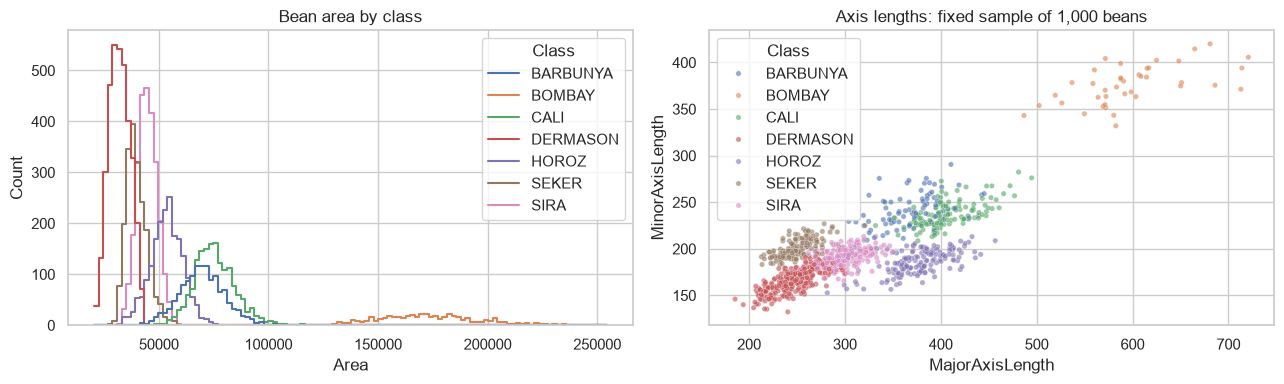

In [3]:
display(df.head())
df.info()
display(df.describe().T)
duplicate_count = int(df.duplicated().sum())
modeling_df = df.drop_duplicates().reset_index(drop=True)
assert not modeling_df.drop(columns="Class").duplicated().any(), "Inspect conflicting duplicate features."
print(f"Removed {duplicate_count} exact duplicates for modeling; {len(modeling_df):,} unique rows remain.")
class_order = sorted(df["Class"].unique())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="Area", hue="Class", element="step", fill=False,
             common_norm=False, hue_order=class_order, ax=axes[0])
axes[0].set_title("Bean area by class")
sns.scatterplot(data=df.sample(n=1000, random_state=SEED), x="MajorAxisLength",
                y="MinorAxisLength", hue="Class", hue_order=class_order, s=15, alpha=0.6, ax=axes[1])
axes[1].set_title("Axis lengths: fixed sample of 1,000 beans")
fig.tight_layout()
plt.show()

## 3. Examine class counts and create stratified splits

Stratification approximately preserves each class proportion in all three sets.
The training set fits model parameters and preprocessing; validation selects
hyperparameters. Keeping the test set until the end limits adaptation to its
particular examples. Fit the class encoder on training labels only.

,train,val,test,Total
BARBUNYA,925,199,198,1322
BOMBAY,366,78,78,522
CALI,1141,244,245,1630
DERMASON,2482,532,532,3546
HOROZ,1302,279,279,1860
SEKER,1419,304,304,2027
SIRA,1845,395,396,2636


,train,val,test
BARBUNYA,0.098,0.098,0.097
BOMBAY,0.039,0.038,0.038
CALI,0.120,0.120,0.121
DERMASON,0.262,0.262,0.262
HOROZ,0.137,0.137,0.137
SEKER,0.150,0.150,0.150
SIRA,0.195,0.194,0.195


Split sizes: {'train': 9480, 'val': 2031, 'test': 2032}


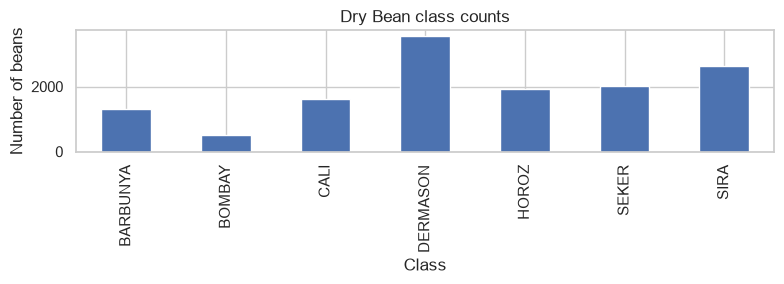

In [4]:
def prepare_dataset(features, labels, name):
    x_train, x_temp, y_train_text, y_temp = train_test_split(
        features, labels, test_size=0.30, random_state=SEED, stratify=labels)
    x_val, x_test, y_val_text, y_test_text = train_test_split(
        x_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)
    encoder = LabelEncoder().fit(y_train_text)
    data = {"name": name, "encoder": encoder, "classes": encoder.classes_,
            "n_features": features.shape[1], "n_classes": len(encoder.classes_)}
    for split, x, y in [("train", x_train, y_train_text),
                        ("val", x_val, y_val_text), ("test", x_test, y_test_text)]:
        data[f"X_{split}_raw"] = x
        data[f"y_{split}"] = encoder.transform(y)
    assert set(x_train.index).isdisjoint(x_val.index)
    assert set(x_train.index).isdisjoint(x_test.index)
    assert set(x_val.index).isdisjoint(x_test.index)
    counts = pd.DataFrame({split: pd.Series(data[f"y_{split}"]).value_counts()
                           .reindex(range(data["n_classes"]), fill_value=0)
                           for split in ("train", "val", "test")})
    counts.index = encoder.classes_
    display(counts.assign(Total=counts.sum(axis=1)))
    display(counts.div(counts.sum(axis=0), axis=1).round(3))
    print("Split sizes:", {s: len(data[f"y_{s}"]) for s in ("train", "val", "test")})
    return data

bean = prepare_dataset(modeling_df.drop(columns="Class"), modeling_df["Class"], "Dry Bean")
df["Class"].value_counts().sort_index().plot.bar(figsize=(8, 3), title="Dry Bean class counts")
plt.ylabel("Number of beans")
plt.tight_layout()
plt.show()

## 4. Scale features and establish a majority-class baseline

Fit `StandardScaler` on training features only, then transform validation and
test features using the same mean and standard deviation. This prevents their
distribution from influencing preprocessing. A majority-class classifier always
predicts the most frequent **training** class. Accuracy and macro F1 together
make its poor treatment of minority classes visible.

In [5]:
def scores(targets, predictions):
    return {"Accuracy": accuracy_score(targets, predictions),
            "Macro F1": f1_score(targets, predictions, average="macro", zero_division=0)}

def scale_and_baseline(data):
    data["scaler"] = StandardScaler().fit(data["X_train_raw"])
    for split in ("train", "val", "test"):
        data[f"X_{split}"] = data["scaler"].transform(data[f"X_{split}_raw"]).astype(np.float32)
    assert np.allclose(data["X_train"].mean(axis=0), 0, atol=1e-5)
    data["dummy"] = DummyClassifier(strategy="most_frequent").fit(
        data["X_train_raw"], data["y_train"])
    baseline_scores = scores(data["y_val"], data["dummy"].predict(data["X_val_raw"]))
    display(pd.DataFrame([baseline_scores], index=["Majority class (validation)"]))
    return baseline_scores

bean_dummy_scores = scale_and_baseline(bean)

,Accuracy,Macro F1
Majority class (validation),0.26194,0.059306


## 5. Build and train the first neural network

The baseline has hidden widths 64 and 32, ReLU activations, dropout 0.2, and Adam
with learning rate 0.001. For a batch of size B the shapes are
`[B, 16] -> [B, 64] -> [B, 64] -> [B, 32] -> [B, 7]`.
The final layer produces logits. `CrossEntropyLoss` combines log-softmax with
negative log likelihood, so no softmax is added before the loss.

The network accepts the number of input features and classes as arguments, so
the same implementation also supports Wine's 13 features and three classes.
Reset seeds and the DataLoader generator for each run. Evaluate training and
validation accuracy after each epoch with dropout disabled, making the reported
generalization gap comparable. Every experiment uses the final epoch, with no
early stopping or best-epoch checkpoint selection.

Input: (4, 16)
Linear: (4, 64)
ReLU: (4, 64)
Dropout: (4, 64)
Linear: (4, 32)
ReLU: (4, 32)
Linear: (4, 7)


,Accuracy,Macro F1,Loss
Baseline NN (validation),0.926145,0.937006,0.210561


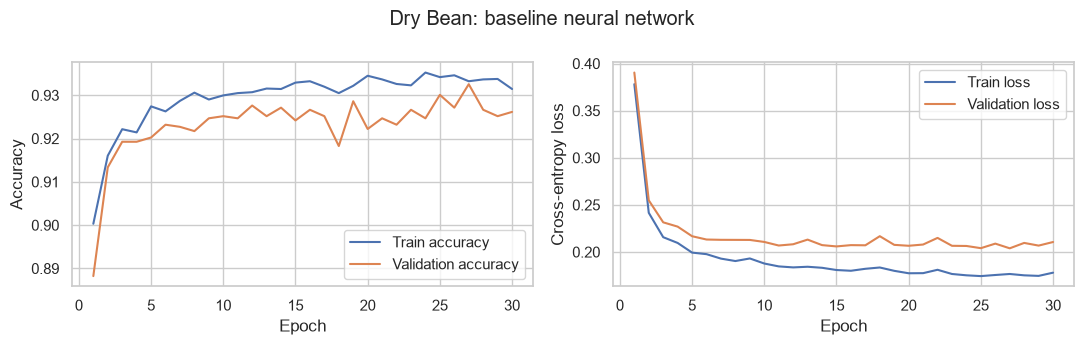

In [6]:
class ClassifierNN(nn.Module):
    def __init__(self, n_features, n_classes, h1=64, h2=32, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, n_classes))

    def forward(self, features):
        return self.net(features)

def make_loader(features, targets, shuffle=False):
    dataset = TensorDataset(torch.tensor(np.asarray(features), dtype=torch.float32),
                            torch.tensor(np.asarray(targets), dtype=torch.long))
    return DataLoader(dataset, batch_size=BATCH_SIZE if shuffle else 512,
                      shuffle=shuffle, generator=torch.Generator().manual_seed(SEED),
                      num_workers=0)

def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    targets, predictions = [], []
    with torch.no_grad():
        for features, labels in loader:
            logits = model(features)
            loss_sum += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
            targets.extend(labels.numpy())
            predictions.extend(logits.argmax(dim=1).numpy())
    metrics = scores(targets, predictions)
    metrics["Loss"] = loss_sum / len(targets)
    return metrics, np.asarray(predictions)

BASE_CONFIG = {"h1": 64, "h2": 32, "dropout": 0.2, "lr": 0.001}

def fit_network(data, config, scaled=True):
    reset_seed()
    suffix = "" if scaled else "_raw"
    x_train, x_val = data[f"X_train{suffix}"], data[f"X_val{suffix}"]
    train_loader = make_loader(x_train, data["y_train"], shuffle=True)
    train_eval_loader = make_loader(x_train, data["y_train"])
    val_loader = make_loader(x_val, data["y_val"])
    model = ClassifierNN(data["n_features"], data["n_classes"],
                         **{k: config[k] for k in ("h1", "h2", "dropout")})
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for features, labels in train_loader:
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(features), labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss; inspect features and learning rate.")
            loss.backward()
            optimizer.step()
        train_metrics, _ = evaluate(model, train_eval_loader)
        val_metrics, _ = evaluate(model, val_loader)
        history.append({"Epoch": epoch, "Train accuracy": train_metrics["Accuracy"],
                        "Validation accuracy": val_metrics["Accuracy"],
                        "Train loss": train_metrics["Loss"], "Validation loss": val_metrics["Loss"]})
    return {"model": model, "config": config.copy(), "history": pd.DataFrame(history),
            "train_metrics": train_metrics, "val_metrics": val_metrics}

def show_history(result, title):
    history = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    history.plot(x="Epoch", y=["Train accuracy", "Validation accuracy"], ax=axes[0])
    history.plot(x="Epoch", y=["Train loss", "Validation loss"], ax=axes[1])
    axes[0].set_ylabel("Accuracy")
    axes[1].set_ylabel("Cross-entropy loss")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

def trace_shapes(model, n_features):
    model.eval()
    batch = torch.zeros(4, n_features)
    print("Input:", tuple(batch.shape))
    with torch.no_grad():
        for layer in model.net:
            batch = layer(batch)
            print(f"{type(layer).__name__}: {tuple(batch.shape)}")

bean_base = fit_network(bean, BASE_CONFIG)
trace_shapes(bean_base["model"], bean["n_features"])
display(pd.DataFrame([bean_base["val_metrics"]], index=["Baseline NN (validation)"]))
show_history(bean_base, "Dry Bean: baseline neural network")

## 6. Compare validation results and investigate errors

Accuracy combines all correct predictions into one number. A confusion matrix
shows which true classes are assigned to other classes; row normalization makes
minority-class recall easier to compare. The classification report adds precision,
recall, and F1 for each class. The code identifies the largest observed confusion
rather than assuming which pair is difficult in advance.

,Accuracy,Macro F1,Loss
Majority class,0.261940,0.059306,NaN
Baseline NN,0.926145,0.937006,0.210561


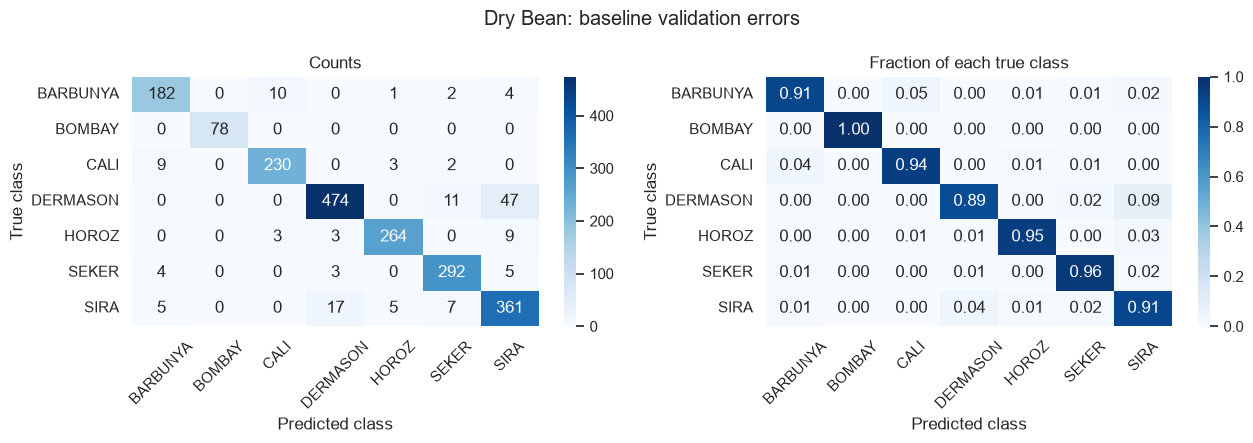

              precision    recall  f1-score   support

    BARBUNYA       0.91      0.91      0.91       199
      BOMBAY       1.00      1.00      1.00        78
        CALI       0.95      0.94      0.94       244
    DERMASON       0.95      0.89      0.92       532
       HOROZ       0.97      0.95      0.96       279
       SEKER       0.93      0.96      0.94       304
        SIRA       0.85      0.91      0.88       395

    accuracy                           0.93      2031
   macro avg       0.94      0.94      0.94      2031
weighted avg       0.93      0.93      0.93      2031

Largest confusion by count: DERMASON -> SIRA (47 examples).


In [7]:
def inspect_errors(data, result, title):
    metrics, predictions = evaluate(result["model"], make_loader(data["X_val"], data["y_val"]))
    labels = np.arange(data["n_classes"])
    cm = confusion_matrix(data["y_val"], predictions, labels=labels)
    normalized = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, matrix, fmt, panel in zip(axes, [cm, normalized], ["d", ".2f"],
                                      ["Counts", "Fraction of each true class"]):
        sns.heatmap(matrix, annot=True, fmt=fmt, cmap="Blues", ax=ax,
                    xticklabels=data["classes"], yticklabels=data["classes"])
        ax.set(title=panel, xlabel="Predicted class", ylabel="True class")
        ax.tick_params(axis="x", rotation=45)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    print(classification_report(data["y_val"], predictions, labels=labels,
                                target_names=[str(c) for c in data["classes"]], zero_division=0))
    errors = cm.copy()
    np.fill_diagonal(errors, 0)
    if errors.sum():
        actual, predicted = np.unravel_index(errors.argmax(), errors.shape)
        print(f"Largest confusion by count: {data['classes'][actual]} -> "
              f"{data['classes'][predicted]} ({errors[actual, predicted]} examples).")
    else:
        print("No validation misclassifications in this run.")
    return metrics

display(pd.DataFrame([bean_dummy_scores, bean_base["val_metrics"]],
                     index=["Majority class", "Baseline NN"]))
inspect_errors(bean, bean_base, "Dry Bean: baseline validation errors");

## 7. Experiment with one model change

Change only dropout from 0.2 to 0.0, leaving the architecture, initialization,
batch order, learning rate, and epoch budget fixed. Higher training accuracy alone
does not show better generalization: compare validation accuracy and the gap
between training and validation. This holds out the test set throughout.

In [8]:
def experiment_row(result, name):
    train = result["train_metrics"]["Accuracy"]
    val = result["val_metrics"]["Accuracy"]
    return {"Experiment": name, **result["config"], "Train accuracy": train,
            "Validation accuracy": val, "Validation macro F1": result["val_metrics"]["Macro F1"],
            "Train-validation gap": train - val}

bean_no_dropout = fit_network(bean, {**BASE_CONFIG, "dropout": 0.0})
display(pd.DataFrame([experiment_row(bean_base, "Baseline"),
                      experiment_row(bean_no_dropout, "Remove dropout")]))
dropout_change = bean_no_dropout["val_metrics"]["Accuracy"] - bean_base["val_metrics"]["Accuracy"]
print(f"Removing dropout changed validation accuracy by {100 * dropout_change:+.2f} percentage points.")

,Experiment,h1,h2,dropout,lr,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,Baseline,64,32,0.2,0.001,0.931435,0.926145,0.937006,0.005290
1,Remove dropout,64,32,0.0,0.001,0.934599,0.923191,0.934371,0.011409


Removing dropout changed validation accuracy by -0.30 percentage points.


## 8. Tune hidden-layer size, dropout, and learning rate

Use a complete 3 x 2 x 2 grid: hidden widths (32,16), (64,32), or (128,64);
dropout 0.0 or 0.2; learning rate 0.001 or 0.01. All 12 configurations use the
same 30 epochs and split. Reuse the two already trained configurations.

The controlled comparison table changes one setting at a time from the baseline.
It identifies the largest absolute validation change among those settings; this
is a result for this split and seed, not a universal ranking of hyperparameters.
The full grid also exposes interactions between settings.

In [9]:
NN_GRID = [{"h1": h1, "h2": h2, "dropout": dropout, "lr": lr}
           for (h1, h2), dropout, lr in product([(32, 16), (64, 32), (128, 64)],
                                               [0.0, 0.2], [0.001, 0.01])]

def config_key(config):
    return tuple(config[k] for k in ("h1", "h2", "dropout", "lr"))

def tune_network(data, initial_results):
    runs = {config_key(r["config"]): r for r in initial_results}
    rows = []
    for config in NN_GRID:
        key = config_key(config)
        if key not in runs:
            runs[key] = fit_network(data, config)
        rows.append(experiment_row(runs[key], str(key)))
    table = pd.DataFrame(rows).sort_values("Validation accuracy", ascending=False, kind="stable")
    best_key = config_key(table.iloc[0].to_dict())
    display(table.reset_index(drop=True))
    controlled = [BASE_CONFIG,
                  {**BASE_CONFIG, "h1": 32, "h2": 16},
                  {**BASE_CONFIG, "h1": 128, "h2": 64},
                  {**BASE_CONFIG, "dropout": 0.0}, {**BASE_CONFIG, "lr": 0.01}]
    base_accuracy = runs[config_key(BASE_CONFIG)]["val_metrics"]["Accuracy"]
    changes = pd.DataFrame([
        {"Change": label,
         "Validation change (percentage points)": 100 * (
             runs[config_key(config)]["val_metrics"]["Accuracy"] - base_accuracy)}
        for label, config in zip(["Baseline", "Smaller hidden layers", "Larger hidden layers",
                                  "Remove dropout", "Higher learning rate"], controlled)])
    display(changes)
    largest = changes.iloc[1:].iloc[changes.iloc[1:, 1].abs().argmax()]
    print(f"Largest absolute one-setting change: {largest.iloc[0]} "
          f"({largest.iloc[1]:+.2f} percentage points).")
    print("Selected NN configuration:", runs[best_key]["config"])
    return runs[best_key], table

bean_best, bean_grid = tune_network(bean, [bean_base, bean_no_dropout])
gain = bean_best["val_metrics"]["Accuracy"] - bean_base["val_metrics"]["Accuracy"]
display(Markdown(f"Selected-grid validation change from baseline: **{100 * gain:+.2f} percentage points**. "
                 "Inspect both training accuracy and the gap in the table before attributing "
                 "a gain to generalization. Repeated validation use can itself overfit the validation set."))

,Experiment,h1,h2,dropout,lr,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,"(32, 16, 0.2, 0.01)",32,16,0.2,0.010,0.934494,0.927622,0.936782,0.006872
1,"(64, 32, 0.2, 0.01)",64,32,0.2,0.010,0.934388,0.926637,0.934902,0.007751
2,"(64, 32, 0.2, 0.001)",64,32,0.2,0.001,0.931435,0.926145,0.937006,0.005290
3,"(128, 64, 0.2, 0.01)",128,64,0.2,0.010,0.941245,0.923683,0.934041,0.017562
4,"(64, 32, 0.0, 0.001)",64,32,0.0,0.001,0.934599,0.923191,0.934371,0.011409
5,"(128, 64, 0.2, 0.001)",128,64,0.2,0.001,0.937553,0.923191,0.934776,0.014362
6,"(64, 32, 0.0, 0.01)",64,32,0.0,0.010,0.940084,0.922698,0.934921,0.017386
7,"(128, 64, 0.0, 0.001)",128,64,0.0,0.001,0.939768,0.922206,0.933643,0.017562
8,"(32, 16, 0.0, 0.001)",32,16,0.0,0.001,0.930907,0.921221,0.932508,0.009686
9,"(32, 16, 0.2, 0.001)",32,16,0.2,0.001,0.929958,0.921221,0.931706,0.008737


,Change,Validation change (percentage points)
0,Baseline,0.000000
1,Smaller hidden layers,-0.492368
2,Larger hidden layers,-0.295421
3,Remove dropout,-0.295421
4,Higher learning rate,0.049237


Largest absolute one-setting change: Smaller hidden layers (-0.49 percentage points).
Selected NN configuration: {'h1': 32, 'h2': 16, 'dropout': 0.2, 'lr': 0.01}


Selected-grid validation change from baseline: **+0.15 percentage points**. Inspect both training accuracy and the gap in the table before attributing a gain to generalization. Repeated validation use can itself overfit the validation set.

## 9. Train without standardizing features

Repeat the baseline with raw features using the same initialization, batch order,
architecture, learning rate, and epoch count. Only feature scaling changes.
Large differences in feature magnitude can dominate gradients and make optimization
harder. Compare measured curves and validation scores; this is a comparison under
the same optimization settings, not a separately tuned unscaled network.

,Experiment,h1,h2,dropout,lr,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,Standardized features,64,32,0.2,0.001,0.931435,0.926145,0.937006,0.005290
1,Raw features,64,32,0.2,0.001,0.684283,0.668636,0.624712,0.015647


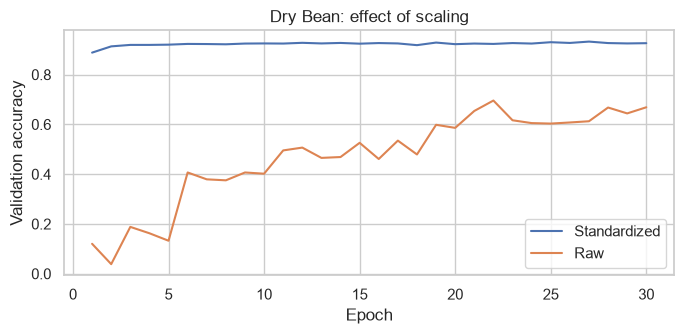

Standardizing changed validation accuracy by +25.75 percentage points.


In [10]:
def compare_scaling(data, baseline):
    unscaled = fit_network(data, BASE_CONFIG, scaled=False)
    display(pd.DataFrame([experiment_row(baseline, "Standardized features"),
                          experiment_row(unscaled, "Raw features")]))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for result, label in [(baseline, "Standardized"), (unscaled, "Raw")]:
        ax.plot(result["history"]["Epoch"], result["history"]["Validation accuracy"], label=label)
    ax.set(title=f"{data['name']}: effect of scaling", xlabel="Epoch", ylabel="Validation accuracy")
    ax.legend()
    fig.tight_layout()
    plt.show()
    difference = baseline["val_metrics"]["Accuracy"] - unscaled["val_metrics"]["Accuracy"]
    print(f"Standardizing changed validation accuracy by {100 * difference:+.2f} percentage points.")
    return unscaled

bean_unscaled = compare_scaling(bean, bean_base)

## 10. Compare with a random forest and tune its hyperparameters

A random forest is a useful learned baseline for tabular data. Tree splits do not
require standardized features, so use raw training measurements. Compare its
default configuration (100 trees) with a complete eight-configuration grid over
tree count, maximum depth, and minimum leaf size. Train only on training data and
rank configurations on the same validation set as the neural networks.

After fixing both selected models, evaluate them and the majority-class baseline
on the test set once. No subsequent choice uses test performance. Macro F1 gives
equal weight to each class, complementing accuracy on this imbalanced dataset.

In [11]:
def tune_forest(data):
    rows, models = [], []
    for trees, depth, leaf in product([100, 200], [None, 12], [1, 3]):
        forest = RandomForestClassifier(n_estimators=trees, max_depth=depth,
                                        min_samples_leaf=leaf, random_state=SEED, n_jobs=2)
        forest.fit(data["X_train_raw"], data["y_train"])
        train_metrics = scores(data["y_train"], forest.predict(data["X_train_raw"]))
        val_metrics = scores(data["y_val"], forest.predict(data["X_val_raw"]))
        rows.append({"Trees": trees, "Maximum depth": str(depth), "Minimum leaf size": leaf,
                     "Train accuracy": train_metrics["Accuracy"], "Validation accuracy": val_metrics["Accuracy"],
                     "Validation macro F1": val_metrics["Macro F1"],
                     "Train-validation gap": train_metrics["Accuracy"] - val_metrics["Accuracy"]})
        models.append(forest)
    table = pd.DataFrame(rows)
    best_index = table["Validation accuracy"].idxmax()
    display(table.sort_values("Validation accuracy", ascending=False, kind="stable"))
    print("Baseline RF validation accuracy:", round(table.iloc[0]["Validation accuracy"], 4))
    print("Selected RF settings:", table.loc[best_index, ["Trees", "Maximum depth", "Minimum leaf size"]].to_dict())
    return models[best_index], table

def final_evaluation(data, neural, forest):
    _, nn_predictions = evaluate(neural["model"], make_loader(data["X_test"], data["y_test"]))
    predictions = {"Majority class": data["dummy"].predict(data["X_test_raw"]),
                   "Selected NN": nn_predictions,
                   "Selected RF": forest.predict(data["X_test_raw"])}
    table = pd.DataFrame({name: scores(data["y_test"], pred)
                          for name, pred in predictions.items()}).T
    display(table.rename_axis("Model (held-out test set)"))
    print(f"Test set size: {len(data['y_test'])}. Model settings are now fixed.")
    return table

bean_forest, bean_forest_grid = tune_forest(bean)
display(pd.DataFrame([
    {"Model": "Baseline NN", **bean_base["val_metrics"]},
    {"Model": "Selected NN", **bean_best["val_metrics"]},
    {"Model": "Baseline RF", "Accuracy": bean_forest_grid.iloc[0]["Validation accuracy"],
     "Macro F1": bean_forest_grid.iloc[0]["Validation macro F1"]},
    {"Model": "Selected RF", **scores(bean["y_val"], bean_forest.predict(bean["X_val_raw"]))}
]).drop(columns="Loss"))
bean_test_scores = final_evaluation(bean, bean_best, bean_forest)

,Trees,Maximum depth,Minimum leaf size,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
4,200,None,1,1.000000,0.922206,0.933705,0.077794
6,200,12,1,0.986920,0.921713,0.932498,0.065206
1,100,None,3,0.976055,0.921221,0.932215,0.054834
0,100,None,1,1.000000,0.920729,0.932486,0.079271
2,100,12,1,0.986076,0.919744,0.931970,0.066332
5,200,None,3,0.976266,0.919744,0.931372,0.056522
7,200,12,3,0.968565,0.919744,0.930865,0.048821
3,100,12,3,0.969198,0.918759,0.930699,0.050439


Baseline RF validation accuracy: 0.9207
Selected RF settings: {'Trees': 200, 'Maximum depth': 'None', 'Minimum leaf size': 1}


,Model,Accuracy,Macro F1
0,Baseline NN,0.926145,0.937006
1,Selected NN,0.927622,0.936782
2,Baseline RF,0.920729,0.932486
3,Selected RF,0.922206,0.933705


,Accuracy,Macro F1
Model (held-out test set),,
Majority class,0.261811,0.059282
Selected NN,0.923720,0.934983
Selected RF,0.919291,0.931710


Test set size: 2032. Model settings are now fixed.


## 11. Repeat the workflow with another dataset: Wine cultivar

Wine contains 178 samples, 13 chemical measurements per sample, and three cultivar
classes. Repeat exploration, stratified splitting, scaling, majority baseline,
network training and shape tracing, validation error analysis, dropout removal,
the same 12-configuration grid, the scaling comparison, and forest tuning before
the final test evaluation. Class labels in scikit-learn are 0-2.

The network input and output dimensions change to 13 and 3; its candidate hidden
widths and training budget stay the same so the comparison is explicit. Wine has
far fewer training examples and batches per epoch, so equal epochs do not imply
equal numbers of optimizer updates across datasets. Its small validation and
test sets also make score differences much more sensitive to individual samples.

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Labels: {0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}


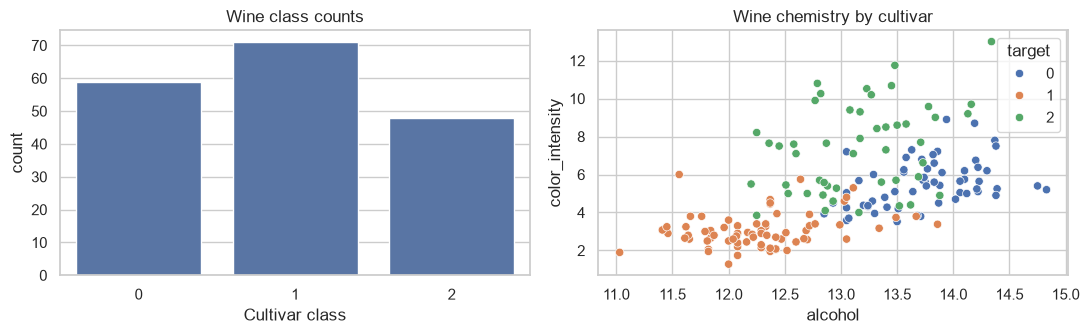

,train,val,test,Total
0,41,9,9,59
1,50,10,11,71
2,33,8,7,48


,train,val,test
0,0.331,0.333,0.333
1,0.403,0.370,0.407
2,0.266,0.296,0.259


Split sizes: {'train': 124, 'val': 27, 'test': 27}


,Accuracy,Macro F1
Majority class (validation),0.37037,0.18018


In [12]:
wine_source = load_wine(as_frame=True)
wine_df = wine_source.frame
assert wine_df.shape == (178, 14)
assert not wine_df.isna().any().any()
display(wine_df.head())
display(wine_df.describe().T)
print("Features:", list(wine_source.data.columns))
print("Labels:", dict(enumerate(wine_source.target_names)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(data=wine_df, x="target", ax=axes[0])
axes[0].set(title="Wine class counts", xlabel="Cultivar class")
sns.scatterplot(data=wine_df, x="alcohol", y="color_intensity", hue="target",
                palette="deep", ax=axes[1])
axes[1].set_title("Wine chemistry by cultivar")
fig.tight_layout()
plt.show()
wine = prepare_dataset(wine_source.data, wine_source.target, "Wine")
wine_dummy_scores = scale_and_baseline(wine)

Input: (4, 13)


Linear: (4, 64)
ReLU: (4, 64)
Dropout: (4, 64)
Linear: (4, 32)
ReLU: (4, 32)
Linear: (4, 3)


,Accuracy,Macro F1,Loss
Majority class,0.370370,0.180180,NaN
Baseline NN,0.962963,0.962848,0.167584


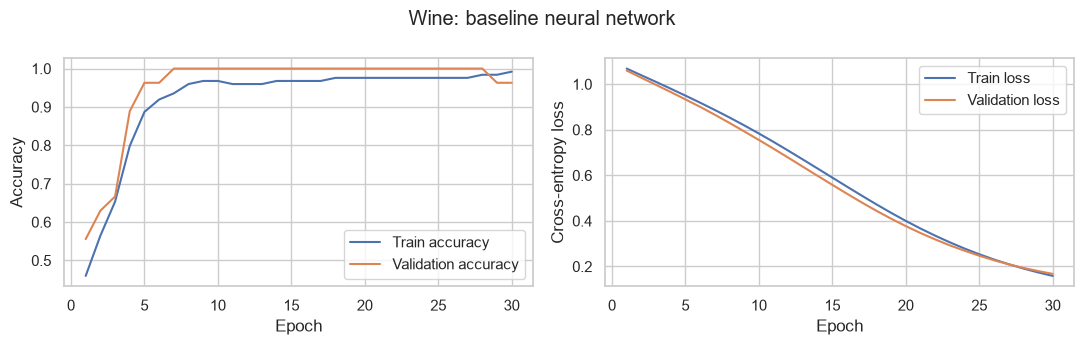

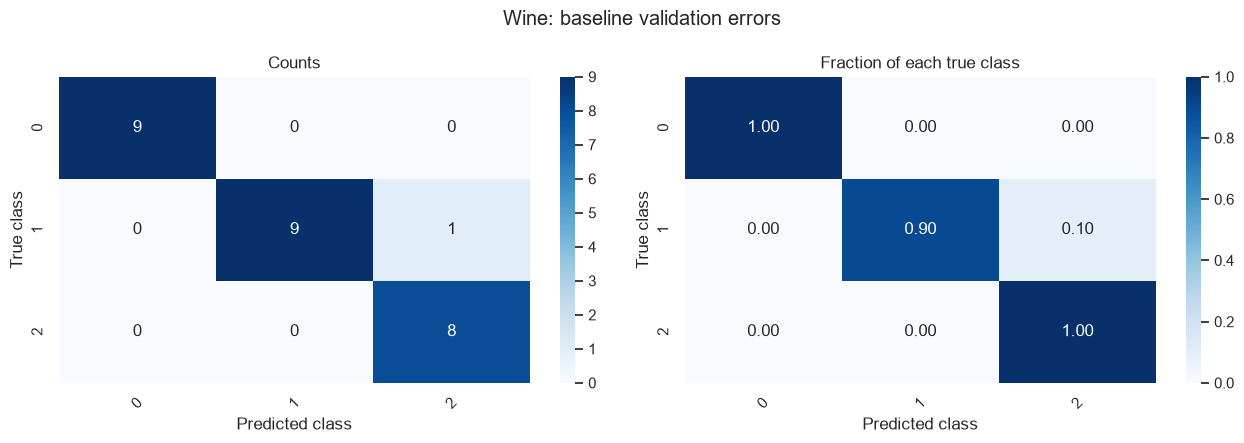

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      0.90      0.95        10
           2       0.89      1.00      0.94         8

    accuracy                           0.96        27
   macro avg       0.96      0.97      0.96        27
weighted avg       0.97      0.96      0.96        27

Largest confusion by count: 1 -> 2 (1 examples).


In [13]:
wine_base = fit_network(wine, BASE_CONFIG)
trace_shapes(wine_base["model"], wine["n_features"])
display(pd.DataFrame([wine_dummy_scores, wine_base["val_metrics"]],
                     index=["Majority class", "Baseline NN"]))
show_history(wine_base, "Wine: baseline neural network")
inspect_errors(wine, wine_base, "Wine: baseline validation errors");

,Experiment,h1,h2,dropout,lr,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,Baseline,64,32,0.2,0.001,0.991935,0.962963,0.962848,0.028973
1,Remove dropout,64,32,0.0,0.001,0.991935,1.000000,1.000000,-0.008065


,Experiment,h1,h2,dropout,lr,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,"(32, 16, 0.0, 0.01)",32,16,0.0,0.010,1.000000,1.000000,1.000000,0.000000
1,"(32, 16, 0.2, 0.01)",32,16,0.2,0.010,1.000000,1.000000,1.000000,0.000000
2,"(64, 32, 0.0, 0.001)",64,32,0.0,0.001,0.991935,1.000000,1.000000,-0.008065
3,"(128, 64, 0.0, 0.001)",128,64,0.0,0.001,0.991935,1.000000,1.000000,-0.008065
4,"(128, 64, 0.2, 0.001)",128,64,0.2,0.001,0.991935,1.000000,1.000000,-0.008065
5,"(64, 32, 0.0, 0.01)",64,32,0.0,0.010,1.000000,0.962963,0.964912,0.037037
6,"(64, 32, 0.2, 0.001)",64,32,0.2,0.001,0.991935,0.962963,0.962848,0.028973
7,"(64, 32, 0.2, 0.01)",64,32,0.2,0.010,1.000000,0.962963,0.964912,0.037037
8,"(128, 64, 0.0, 0.01)",128,64,0.0,0.010,1.000000,0.962963,0.962848,0.037037
9,"(128, 64, 0.2, 0.01)",128,64,0.2,0.010,1.000000,0.962963,0.964912,0.037037


,Change,Validation change (percentage points)
0,Baseline,0.000000
1,Smaller hidden layers,-7.407407
2,Larger hidden layers,3.703704
3,Remove dropout,3.703704
4,Higher learning rate,0.000000


Largest absolute one-setting change: Smaller hidden layers (-7.41 percentage points).
Selected NN configuration: {'h1': 32, 'h2': 16, 'dropout': 0.0, 'lr': 0.01}


,Experiment,h1,h2,dropout,lr,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,Standardized features,64,32,0.2,0.001,0.991935,0.962963,0.962848,0.028973
1,Raw features,64,32,0.2,0.001,0.556452,0.703704,0.689794,-0.147252


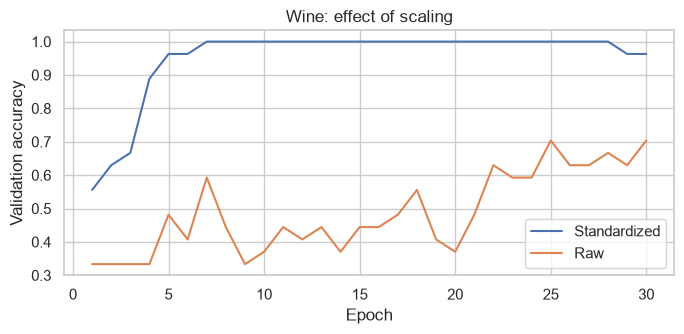

Standardizing changed validation accuracy by +25.93 percentage points.


,Trees,Maximum depth,Minimum leaf size,Train accuracy,Validation accuracy,Validation macro F1,Train-validation gap
0,100,None,1,1.0,1.0,1.0,0.0
1,100,None,3,1.0,1.0,1.0,0.0
2,100,12,1,1.0,1.0,1.0,0.0
3,100,12,3,1.0,1.0,1.0,0.0
4,200,None,1,1.0,1.0,1.0,0.0
5,200,None,3,1.0,1.0,1.0,0.0
6,200,12,1,1.0,1.0,1.0,0.0
7,200,12,3,1.0,1.0,1.0,0.0


Baseline RF validation accuracy: 1.0
Selected RF settings: {'Trees': 100, 'Maximum depth': 'None', 'Minimum leaf size': 1}


,Accuracy,Macro F1
Model (held-out test set),,
Majority class,0.407407,0.192982
Selected NN,0.962963,0.959866
Selected RF,1.000000,1.000000


Test set size: 27. Model settings are now fixed.


In [14]:
wine_no_dropout = fit_network(wine, {**BASE_CONFIG, "dropout": 0.0})
display(pd.DataFrame([experiment_row(wine_base, "Baseline"),
                      experiment_row(wine_no_dropout, "Remove dropout")]))
wine_best, wine_grid = tune_network(wine, [wine_base, wine_no_dropout])
wine_unscaled = compare_scaling(wine, wine_base)
wine_forest, wine_forest_grid = tune_forest(wine)
wine_test_scores = final_evaluation(wine, wine_best, wine_forest)

### Compare measured outcomes across datasets

The table below contrasts the selected settings and validation gains for both
problems. Scores belong to different tasks and sample sizes; they should not be
interpreted as a direct ranking of dataset difficulty. The final test results
estimate performance of the fixed models on their respective held-out samples.
Multiple seeds or cross-validation would be needed to assess whether small
hyperparameter differences persist beyond this split.

In [15]:
comparison_rows = []
for data, base, best, forest_table, unscaled, test_scores in [
        (bean, bean_base, bean_best, bean_forest_grid, bean_unscaled, bean_test_scores),
        (wine, wine_base, wine_best, wine_forest_grid, wine_unscaled, wine_test_scores)]:
    nn_gain = 100 * (best["val_metrics"]["Accuracy"] - base["val_metrics"]["Accuracy"])
    rf_gain = 100 * (forest_table["Validation accuracy"].max() - forest_table.iloc[0]["Validation accuracy"])
    comparison_rows.append({"Dataset": data["name"], "Training rows": len(data["y_train"]),
        "Features / classes": f"{data['n_features']} / {data['n_classes']}",
        "Selected NN settings": str(best["config"]),
        "NN validation gain (pp)": nn_gain, "RF validation gain (pp)": rf_gain,
        "Scaled - raw NN validation (pp)": 100 * (base["val_metrics"]["Accuracy"] - unscaled["val_metrics"]["Accuracy"]),
        "NN test accuracy": test_scores.loc["Selected NN", "Accuracy"],
        "RF test accuracy": test_scores.loc["Selected RF", "Accuracy"]})
    print(f"{data['name']}: NN tuning changed validation accuracy by {nn_gain:+.2f} pp; "
          f"RF tuning changed it by {rf_gain:+.2f} pp.")
display(pd.DataFrame(comparison_rows).set_index("Dataset").T)

Dry Bean: NN tuning changed validation accuracy by +0.15 pp; RF tuning changed it by +0.15 pp.
Wine: NN tuning changed validation accuracy by +3.70 pp; RF tuning changed it by +0.00 pp.


Dataset,Dry Bean,Wine
Training rows,9480,124
Features / classes,16 / 7,13 / 3
Selected NN settings,"{'h1': 32, 'h2': 16, 'dropout': 0.2, 'lr': 0.01}","{'h1': 32, 'h2': 16, 'dropout': 0.0, 'lr': 0.01}"
NN validation gain (pp),0.14771,3.703704
RF validation gain (pp),0.14771,0.0
Scaled - raw NN validation (pp),25.750862,25.925926
NN test accuracy,0.92372,0.962963
RF test accuracy,0.919291,1.0


### References

- Workshop requirements: `Monday-Workshop (1).pdf`, pages 1-2.
- [UCI Dry Bean dataset](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset),
  [DOI: 10.24432/C50S4B](https://doi.org/10.24432/C50S4B).
- [scikit-learn Wine dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).
- [PyTorch Linear layers](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)
  and [reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).